# Logistic Regression


This notebook implements a logistic regression as a baseline model to predict death probabilities from clinical and molecular data.


In [1]:
import matplotlib.pyplot as plt
import pandas as pd

from src.eval_utils import full_evaluation
from src.modeltrainer import ModelML, find_existing_model

In [2]:
# =============================================================================
# CELL 1: LOAD DATA
# =============================================================================


# Configuration
DATA_PATH = 'data/processed_data_imputed.xlsx'
COLS_TO_DROP = ['patient_ids', 'feat_40', 'feat_82']

# Load the three splits
print("Loading data...")

train_data = pd.read_excel(DATA_PATH, sheet_name='train')
cal_data = pd.read_excel(DATA_PATH, sheet_name='calibration')
test_data = pd.read_excel(DATA_PATH, sheet_name='test')

# Split features / target
X_train = train_data.iloc[:, :-1].drop(columns=COLS_TO_DROP, errors='ignore')
y_train = train_data.iloc[:, -1]


X_test = test_data.iloc[:, :-1].drop(columns=COLS_TO_DROP, errors='ignore')
y_test = test_data.iloc[:, -1]

print("Data loaded:")
print(f"   - Train: {X_train.shape[0]} lignes, {X_train.shape[1]} features")
print(f"   - Test: {X_test.shape[0]} lignes")
print(f"   - Target distribution (train): {y_train.value_counts().to_dict()}")

Loading data...
Data loaded:
   - Train: 445575 lignes, 81 features
   - Test: 56938 lignes
   - Target distribution (train): {0: 249063, 1: 196512}


In [3]:
# =============================================================================
# CELL 2: LOAD OR TRAIN THE MODEL
# =============================================================================


# Configuration
MODEL_DIR = 'models'
MODEL_TYPE = 'LogisticRegression'  # 'LogisticRegression', 'RandomForest', 'XGBoost'



# Initialise the trainer
trainer = ModelML(
    x_train=X_train,
    x_test=X_test,
    y_train=y_train,
    y_test=y_test
)

# Reuse a saved model if one exists, otherwise tune and train
existing_model = find_existing_model(MODEL_DIR, MODEL_TYPE)

if existing_model:
    print(f"Found saved model: {existing_model}")
    trainer.load_model(existing_model)
else:
    print(f"No saved {MODEL_TYPE} model found. Training...")
    
    if MODEL_TYPE == 'LogisticRegression':
        trainer.tune_logistic_regression(
            param_grid={
                'C': [0.01, 0.1, 1, 10],
                'penalty': ['l2'],
                'solver': ['liblinear'],
                'class_weight': [None, 'balanced']
            },
            method='grid',
            cv=5,
            scoring='roc_auc'
        )
    
    elif MODEL_TYPE == 'RandomForest':
        trainer.tune_random_forest(
            param_grid={
                'n_estimators': [50, 100, 200],
                'max_depth': [3, 5, 10, None],
                'min_samples_leaf': [1, 2],
                'max_features': ['sqrt']
            },
            method='random',
            n_iter=20,
            cv=5,
            scoring='roc_auc'
        )
    
    elif MODEL_TYPE == 'XGBoost':
        trainer.tune_xgboost(
            param_grid={
                'n_estimators': [50, 100, 200],
                'max_depth': [3, 5, 7],
                'learning_rate': [0.01, 0.1],
                'subsample': [0.6, 0.8, 1.0]
            },
            method='random',
            n_iter=20,
            cv=5,
            scoring='roc_auc'
        )
    
    trainer.save_model()
    print("Model trained and saved")

print(f"\nActive model: {trainer.model_name}")
print(f"   Parameters: {trainer.best_params}")

No saved LogisticRegression model found. Training...

Hyperparameter search (GRID)
   Model: logistic_regression_tuned
   Scoring: roc_auc
   CV folds: 5
   Parameters searched: ['C', 'penalty', 'solver', 'class_weight']
Fitting 5 folds for each of 8 candidates, totalling 40 fits


/mnt/12f6cfec-e85b-498f-b7be-df4d2207236a/home-mouad/venvs/masef/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
/mnt/12f6cfec-e85b-498f-b7be-df4d2207236a/home-mouad/venvs/masef/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf 


Best parameters found:
   - C: 0.1
   - class_weight: balanced
   - penalty: l2
   - solver: liblinear
   - Best CV Score (roc_auc): 0.8063

Results:
   - Train Accuracy: 0.7308
   - Test Accuracy:  0.7059
Model saved: models/logistic_regression_tuned.pkl
Parameters saved: models/logistic_regression_tuned_params.json
Model trained and saved

Active model: logistic_regression_tuned
   Parameters: {'C': 0.1, 'class_weight': 'balanced', 'penalty': 'l2', 'solver': 'liblinear'}



TEST SET EVALUATION

FULL EVALUATION: logistic_regression_tuned_test
EVALUATION METRICS

Classification metrics:
----------------------------------------
   Accuracy                 : 0.7059
   Balanced_Accuracy        : 0.7052
   Precision                : 0.6680
   Recall_Sensitivity       : 0.6982
   Specificity              : 0.7123
   F1_Score                 : 0.6827
   Matthews_Corr_Coef       : 0.4092
   Cohen_Kappa              : 0.4089

Probabilistic metrics:
----------------------------------------
   ROC_AUC                  : 0.7761
   PR_AUC                   : 0.7285
   Brier_Score              : 0.1928
   Log_Loss                 : 0.5679

CLASSIFICATION REPORT
              precision    recall  f1-score   support

     Class 0       0.74      0.71      0.73     31128
     Class 1       0.67      0.70      0.68     25810

    accuracy                           0.71     56938
   macro avg       0.70      0.71      0.70     56938
weighted avg       0.71      0.71      0.

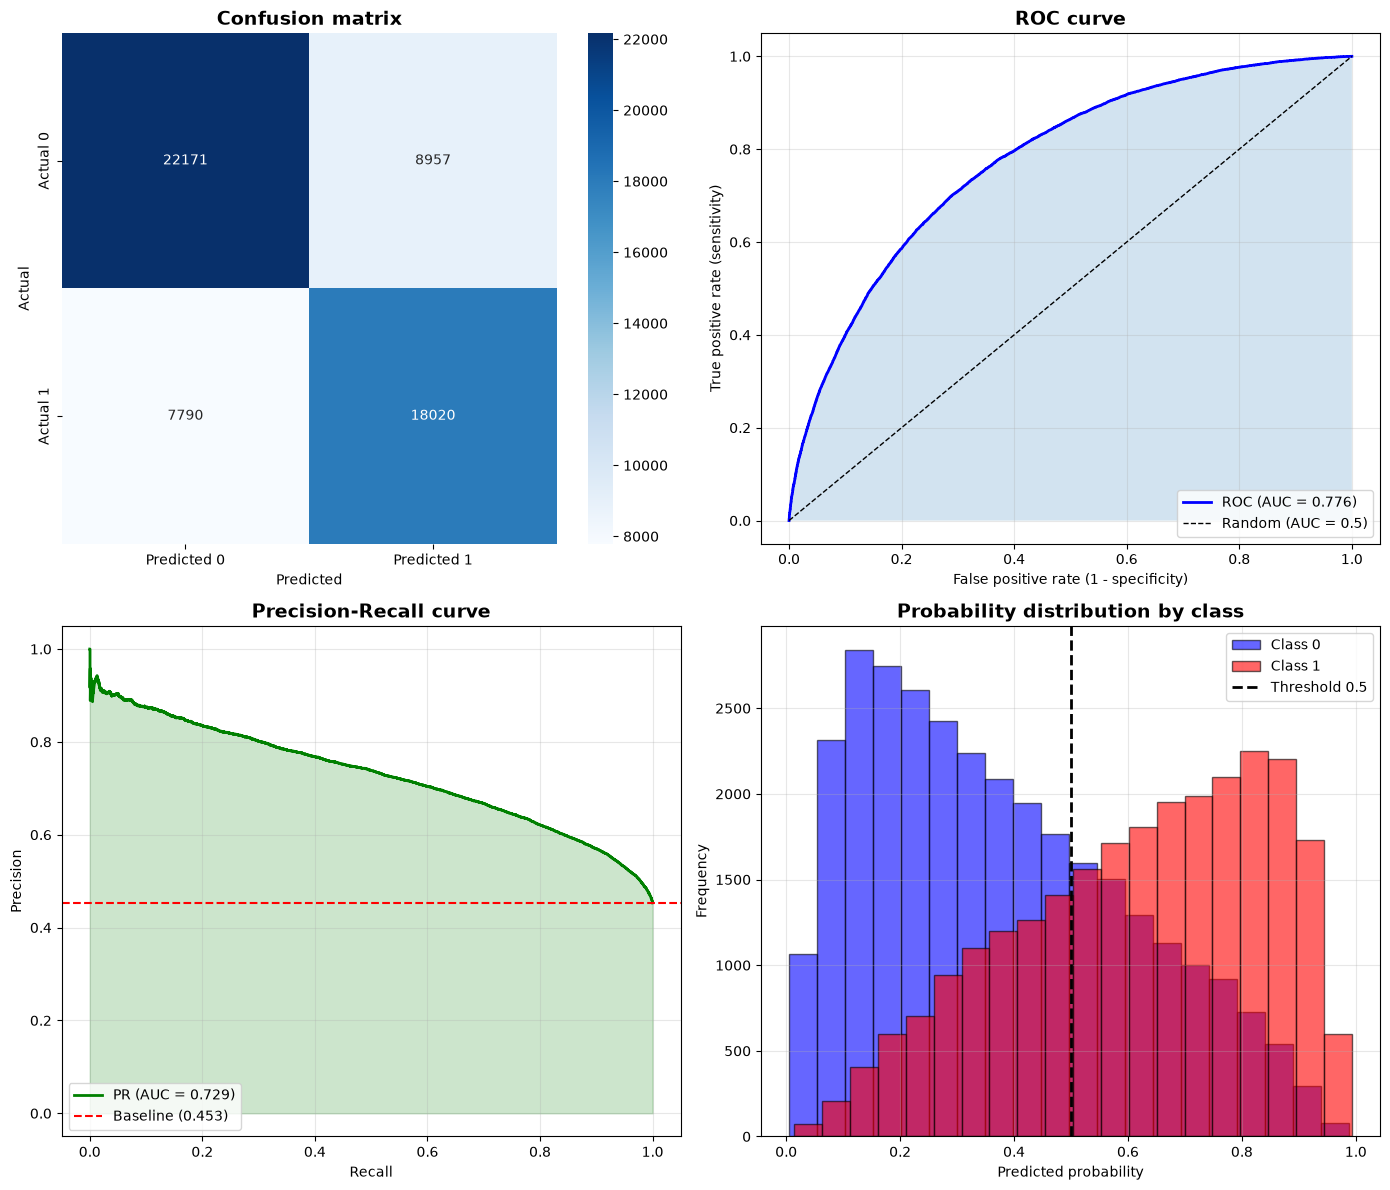

In [4]:
# =============================================================================
# CELL 3: FULL EVALUATION ON THE TEST SET
# =============================================================================


print("\n" + "="*70)
print("TEST SET EVALUATION")
print("="*70)

y_pred_test = trainer.predict(X_test)
y_proba_test = trainer.predict_proba(X_test)[:, 1]

metrics_test = full_evaluation(
    y_true=y_test,
    y_pred=y_pred_test,
    y_proba=y_proba_test,
    model_name=f"{trainer.model_name}_test",
    save_dir='results'
)

# Show the plots
plt.show()

## Logistic Regression Results Analysis

### Model Performance (test pairs)
- **ROC-AUC: 0.776**: the highest of the four models (random forest 0.770, XGBoost 0.761, gradient boosting 0.760)
- **Accuracy: 70.6%**
- **Brier Score: 0.193**: the lowest of the four models (random forest 0.195)
- **Log Loss: 0.568**: the lowest of the four models (random forest 0.573)

Logistic regression directly minimises the log loss, so its probabilities are well calibrated by construction. Post-hoc calibration confirms this: Platt scaling slightly worsens it (Brier 0.1928 → 0.1932, log loss 0.568 → 0.569), and so does isotonic regression (log loss 0.568 → 0.571).

